# Solving the n-Queens Problem using Local Search

Student Name: Pham Thai Duy Khang

I have used the following AI tools: chat GPT and Gemini

I understand that my submission needs to be my own work: Khang


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

Để chạy trên máy, chọn kernel Python có `numpy`, `matplotlib`, `pandas`. Nếu thiếu, chạy `%pip install numpy matplotlib pandas` trong một cell riêng. Cell Drive bên dưới tự bỏ qua khi không dùng Colab. Chạy từ trên xuống; các seed cố định giúp lặp lại kết quả chất lượng, còn thời gian phụ thuộc máy. Bảng Markdown Task 6 lưu kết quả lần chạy đã thực hiện; bảng do code sinh ra sẽ cập nhật khi chạy lại. Phần GA cuối bài là tùy chọn và chưa triển khai.

In [15]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


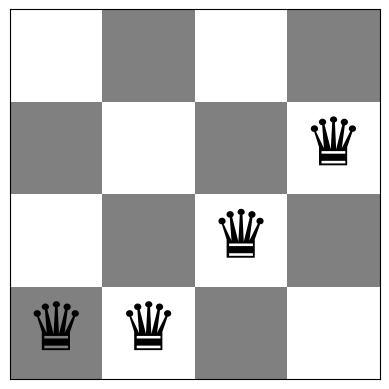

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [17]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


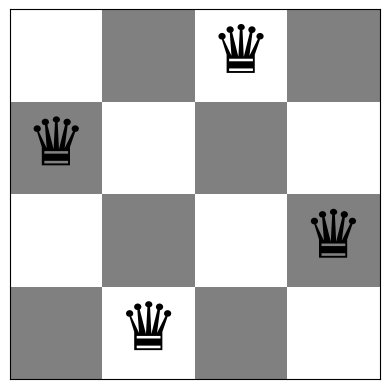

In [18]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Thuật toán duyệt toàn bộ nước đi và nhận nước giảm xung đột nhiều nhất. Nếu bằng điểm tốt nhất, giữ ứng viên xuất hiện trước. Dừng ở nghiệm 0 hoặc trạng thái không có láng giềng tốt hơn; không nhận bước ngang. Mỗi lần đánh giá `conflicts` được đếm để hỗ trợ so sánh.

Initial: 9 Final: 2
Board with 2 conflicts.


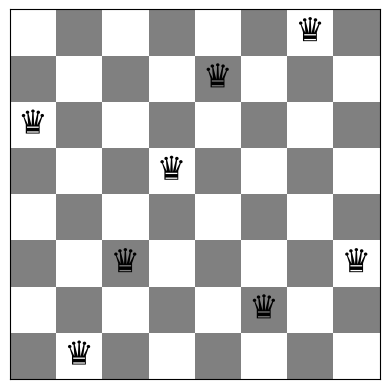

In [19]:
import time
import math
import pandas as pd
from IPython.display import display

# Each result stores the final board and the conflicts after every attempted step.
def make_result(board, history, evaluations):
    return {"board": np.array(board, copy=True), "conflicts": conflicts(board),
            "history": history, "evaluations": evaluations}

def neighbors(board):
    for col in range(len(board)):
        for row in range(len(board)):
            if row != board[col]:
                candidate = np.array(board, copy=True)
                candidate[col] = row
                yield candidate

def steepest_hc(board, rng=None):
    board = np.array(board, copy=True)
    score = conflicts(board)
    history, evaluations = [score], 0
    while score > 0:
        best, best_score = board, score
        for candidate in neighbors(board):
            value = conflicts(candidate)
            evaluations += 1
            if value < best_score:
                best, best_score = candidate, value
        if best_score == score:
            break
        board, score = best, best_score
        history.append(score)
    return make_result(board, history, evaluations)

example = np.random.default_rng(42).integers(0, 8, size=8)
r = steepest_hc(example)
print("Initial:", conflicts(example), "Final:", r["conflicts"])
show_board(r["board"], fontsize=24)


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

Thuật toán lập danh sách tất cả nước giảm xung đột, chọn đều ngẫu nhiên một nước. Vẫn tốn chi phí duyệt toàn bộ lân cận; thuật toán không bảo đảm đạt nghiệm.

In [20]:
def inefficient_stochastic_hc(board, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    board = np.array(board, copy=True)
    score = conflicts(board)
    history, evaluations = [score], 0
    while score > 0:
        improvements = []
        for candidate in neighbors(board):
            value = conflicts(candidate)
            evaluations += 1
            if value < score:
                improvements.append((candidate, value))
        if not improvements:
            break
        board, score = improvements[int(rng.integers(len(improvements)))]
        history.append(score)
    return make_result(board, history, evaluations)

r = inefficient_stochastic_hc(example, np.random.default_rng(42))
print("Final conflicts:", r["conflicts"])


Final conflicts: 2


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Với $m=n(n-1)$ nước đi, chọn $x=\lceil m\ln(m/0.01)\rceil$ lần thất bại liên tiếp. Khi trạng thái cố định và lấy mẫu đều có lặp, xác suất còn ít nhất một nước chưa được thử không quá $m e^{-x/m}\leq0.01$ (union bound). Đây là bảo đảm xác suất cho một giai đoạn tại trạng thái cố định, không phải chứng nhận cực tiểu hay bảo đảm 99% cho toàn bộ lần chạy. Đặt lại bộ đếm sau mỗi cải thiện.

In [21]:
def single_move(board, rng):
    candidate = np.array(board, copy=True)
    n = len(board)
    col = int(rng.integers(n))
    # Select uniformly among the n-1 rows other than the current row.
    row = int(rng.integers(n - 1))
    candidate[col] = row + (row >= board[col])
    return candidate

def failure_limit(n, delta=0.01):
    m = n * (n - 1)
    return max(1, math.ceil(m * math.log(max(m, 1) / delta)))

def efficient_stochastic_hc(board, rng=None, patience=None, move=single_move):
    rng = np.random.default_rng() if rng is None else rng
    board = np.array(board, copy=True)
    score = conflicts(board)
    history, evaluations, failures = [score], 0, 0
    patience = failure_limit(len(board)) if patience is None else patience
    while score > 0 and failures < patience:
        candidate = move(board, rng)
        value = conflicts(candidate)
        evaluations += 1
        if value < score:
            board, score, failures = candidate, value, 0
        else:
            failures += 1
        history.append(score)
    return make_result(board, history, evaluations)

r = efficient_stochastic_hc(example, np.random.default_rng(42))
print("Final conflicts:", r["conflicts"], "Evaluations:", r["evaluations"])


Final conflicts: 1 Evaluations: 533


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Thuật toán được khởi động lại tối đa 100 lần sau lần chạy đầu, tức tối đa 101 lần chạy. Giữ nghiệm tốt nhất và dừng sớm ở 0. Bảng minh họa dùng n=8.

In [22]:
HC_ALGORITHMS = {"Steepest HC": steepest_hc,
                 "Inefficient stochastic HC": inefficient_stochastic_hc,
                 "Efficient stochastic HC": efficient_stochastic_hc}

def random_restart(search, n, rng, max_restarts=100):
    best = None
    total_evaluations = 0
    # Initial run plus at most 100 restarts.
    for run in range(max_restarts + 1):
        result = search(rng.integers(0, n, size=n), rng=rng)
        total_evaluations += result["evaluations"]
        if best is None or result["conflicts"] < best["conflicts"]:
            best = result
        if best["conflicts"] == 0:
            break
    return {**best, "runs": run + 1, "total_evaluations": total_evaluations}

restart_rows = []
for name, search in HC_ALGORITHMS.items():
    start = time.perf_counter()
    result = random_restart(search, 8, np.random.default_rng(2026))
    restart_rows.append({"Algorithm": name, "Runs": result["runs"],
                         "Final conflicts": result["conflicts"],
                         "Seconds": time.perf_counter() - start})
display(pd.DataFrame(restart_rows))


,Algorithm,Runs,Final conflicts,Seconds
0,Steepest HC,3,0,0.003195
1,Inefficient stochastic HC,7,0,0.009934
2,Efficient stochastic HC,1,0,0.000890


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

Với $\Delta=f(q_{new})-f(q)$, nhận khi $\Delta\leq0$, còn lại nhận với xác suất $e^{-\Delta/T}$. Dùng $T_k=3\alpha^k$, tối đa 4000 bước. Thử ba lịch trên cùng 30 bàn cờ; benchmark giữ cấu hình mặc định alpha=0.995 để không lựa chọn theo bộ test. Đường cong ghi trạng thái hiện tại, có thể tăng điểm.

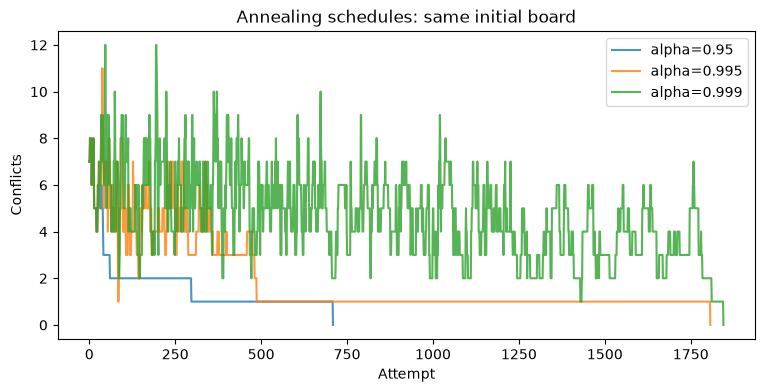

,alpha,Mean final conflicts,Success (%),Mean attempts
0,0.950,0.000000,100.000000,719.300000
1,0.995,0.000000,100.000000,878.666667
2,0.999,0.033333,96.666667,1883.966667


Trong thí nghiệm này, alpha=0.95 có tỷ lệ thành công cao nhất (ưu tiên ít xung đột hơn nếu bằng nhau). Giảm nhiệt nhanh có thể đóng băng sớm; giảm chậm cho phép khám phá lâu hơn nhưng có thể cần nhiều bước hơn. Đây là kết quả trên 30 bàn cờ, không bảo đảm thứ hạng cho mọi bộ dữ liệu.


In [23]:
def simulated_annealing(board, rng=None, t0=3.0, alpha=0.995, max_steps=4000):
    rng = np.random.default_rng() if rng is None else rng
    board = np.array(board, copy=True)
    score = conflicts(board)
    history, evaluations = [score], 0
    for step in range(max_steps):
        if score == 0:
            break
        temperature = max(t0 * alpha ** step, 1e-12)
        candidate = single_move(board, rng)
        value = conflicts(candidate)
        delta = value - score
        evaluations += 1
        if delta <= 0 or rng.random() < math.exp(-delta / temperature):
            board, score = candidate, value
        history.append(score)
    # Return the final state (not the best state), consistent with the table metric.
    return make_result(board, history, evaluations)

schedule_rows = []
schedule_boards = np.random.default_rng(91).integers(0, 8, size=(30, 8))
fig, ax = plt.subplots(figsize=(9, 4))
for alpha in [0.95, 0.995, 0.999]:
    results = [simulated_annealing(b, np.random.default_rng(300+i), alpha=alpha)
               for i, b in enumerate(schedule_boards)]
    schedule_rows.append({"alpha": alpha,
                          "Mean final conflicts": np.mean([r["conflicts"] for r in results]),
                          "Success (%)": 100*np.mean([r["conflicts"] == 0 for r in results]),
                          "Mean attempts": np.mean([r["evaluations"] for r in results])})
    ax.plot(results[0]["history"], label=f"alpha={alpha}", alpha=0.8)
ax.set(xlabel="Attempt", ylabel="Conflicts", title="Annealing schedules: same initial board")
ax.legend()
plt.show()
schedule_df = pd.DataFrame(schedule_rows)
display(schedule_df)
best_schedule = schedule_df.sort_values(["Success (%)", "Mean final conflicts"],
                                        ascending=[False, True]).iloc[0]
print(f"Trong thí nghiệm này, alpha={best_schedule['alpha']} có tỷ lệ thành công cao nhất "
      "(ưu tiên ít xung đột hơn nếu bằng nhau). Giảm nhiệt nhanh có thể đóng băng sớm; "
      "giảm chậm cho phép khám phá lâu hơn nhưng có thể cần nhiều bước hơn. "
      "Đây là kết quả trên 30 bàn cờ, không bảo đảm thứ hạng cho mọi bộ dữ liệu.")


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm | Board size | Avg. Run time (s) | Avg. number of conflicts | Optimal (%) |
| --- | --- | --- | --- | --- |
| Steepest HC | 4 | 0.00007 | 0.78 | 33.0 |
| Inefficient stochastic HC | 4 | 0.00009 | 0.85 | 27.0 |
| Efficient stochastic HC | 4 | 0.00034 | 0.89 | 24.0 |
| Simulated annealing | 4 | 0.00036 | 0.00 | 100.0 |
| Steepest HC | 8 | 0.00097 | 1.12 | 19.0 |
| Inefficient stochastic HC | 8 | 0.00131 | 1.23 | 13.0 |
| Efficient stochastic HC | 8 | 0.00310 | 1.37 | 12.0 |
| Simulated annealing | 8 | 0.00567 | 0.00 | 100.0 |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

Mỗi kích thước được thử trên 100 bàn cờ. Bốn thuật toán dùng cùng tập đầu vào và seed cố định; thời gian được đo bằng `perf_counter`. Không tính thời gian vẽ/in. Báo cáo trạng thái cuối, không phải điểm tốt nhất từng đi qua. Các phép đo gồm chi phí lưu lịch sử; kết quả phụ thuộc máy và tải hệ thống.

In [24]:
ALGORITHMS = {**HC_ALGORITHMS, "Simulated annealing": simulated_annealing}
benchmark_rows = []
# All algorithms use exactly the same 100 initial boards for each n.
# These are independent single runs, not random-restart runs.
for n_size in [4, 8]:
    initial_boards = np.random.default_rng(1000+n_size).integers(0, n_size, size=(100, n_size))
    for name, search in ALGORITHMS.items():
        times, scores, evals = [], [], []
        for i, board in enumerate(initial_boards):
            rng = np.random.default_rng(2000+i)
            start = time.perf_counter()
            result = search(board, rng=rng)
            times.append(time.perf_counter()-start)
            scores.append(result["conflicts"])
            evals.append(result["evaluations"])
        benchmark_rows.append({"Algorithm": name, "Board size": n_size,
                              "Avg. Run time (s)": np.mean(times),
                              "Avg. number of conflicts": np.mean(scores),
                              "Optimal (%)": 100*np.mean(np.array(scores) == 0),
                              "Avg. evaluations": np.mean(evals)})
benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df.round(5))
for n_size in [4, 8]:
    subset = benchmark_df[benchmark_df["Board size"] == n_size]
    fastest = subset.loc[subset["Avg. Run time (s)"].idxmin(), "Algorithm"]
    successful = subset.loc[subset["Optimal (%)"].idxmax(), "Algorithm"]
    print(f"n={n_size}: nhanh nhất trung bình: {fastest}; tỷ lệ thành công cao nhất: {successful}.")


,Algorithm,Board size,Avg. Run time (s),Avg. number of conflicts,Optimal (%),Avg. evaluations
0,Steepest HC,4,0.00007,0.78,33.0,26.28
1,Inefficient stochastic HC,4,0.00009,0.85,27.0,31.56
2,Efficient stochastic HC,4,0.00034,0.89,24.0,74.93
3,Simulated annealing,4,0.00035,0.00,100.0,74.73
4,Steepest HC,8,0.00090,1.12,19.0,217.28
5,Inefficient stochastic HC,8,0.00128,1.23,13.0,301.28
6,Efficient stochastic HC,8,0.00310,1.37,12.0,494.93
7,Simulated annealing,8,0.00573,0.00,100.0,867.88


n=4: nhanh nhất trung bình: Steepest HC; tỷ lệ thành công cao nhất: Simulated annealing.
n=8: nhanh nhất trung bình: Steepest HC; tỷ lệ thành công cao nhất: Simulated annealing.


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

Hill climbing giảm nhanh qua các bước được nhận nhưng có thể kết thúc ở điểm >0. First-choice có các đoạn ngang do nước bị từ chối. SA có dao động khi nhiệt cao. Một lần chạy chỉ minh họa; dùng tỷ lệ thất bại ở bảng benchmark để đánh giá mức độ thường xuyên bị kẹt.

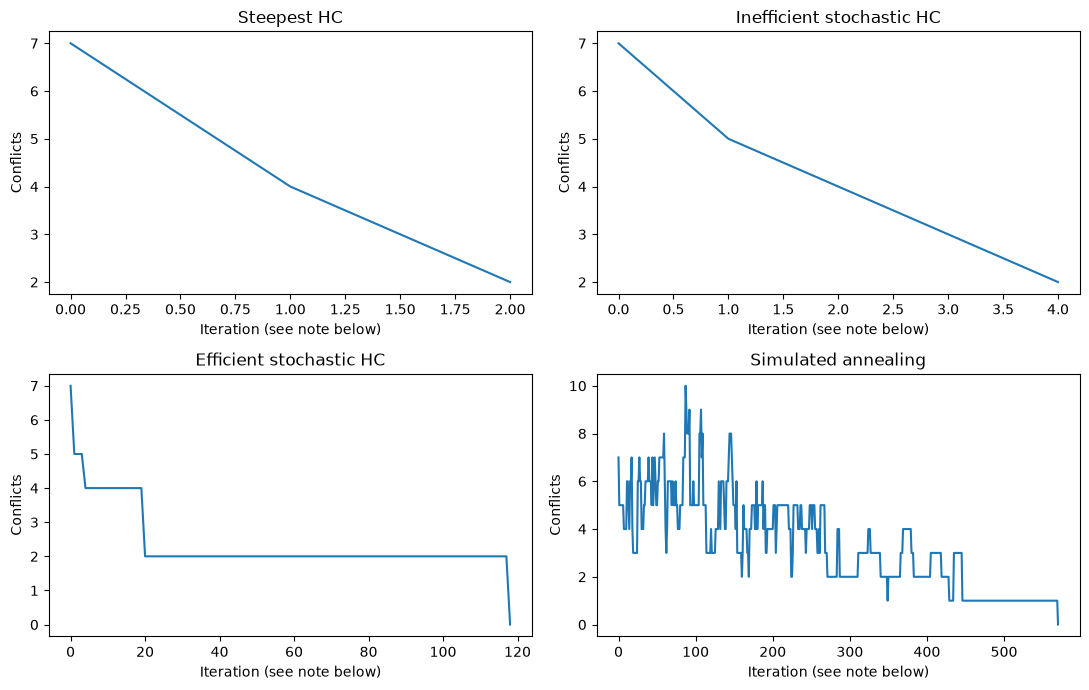

,Algorithm,Final conflicts
0,Steepest HC,2
1,Inefficient stochastic HC,2
2,Efficient stochastic HC,0
3,Simulated annealing,0


Task 1–2: một iteration là một bước cải thiện sau khi duyệt toàn bộ lân cận. Task 3 và SA: một iteration là một lần thử, kể cả bị từ chối. Do đó không dùng trục iteration để kết luận thuật toán nào nhanh hơn.
Hill climbing chỉ giảm điểm và dừng khi bị kẹt; first-choice thể hiện các đoạn ngang khi thử thất bại. SA có thể tăng điểm trước khi giảm, nhờ chấp nhận nước xấu. Tần suất thất bại được đánh giá bằng bảng 100 lần chạy, không suy ra từ một đồ thị.


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
convergence_rows = []
start_board = np.random.default_rng(123).integers(0, 8, size=8)
for ax, (name, search) in zip(axes.flat, ALGORITHMS.items()):
    result = search(start_board, rng=np.random.default_rng(456))
    ax.plot(result["history"])
    ax.set(title=name, xlabel="Iteration (see note below)", ylabel="Conflicts")
    convergence_rows.append({"Algorithm": name, "Final conflicts": result["conflicts"]})
plt.tight_layout()
plt.show()
display(pd.DataFrame(convergence_rows))
print("Task 1–2: một iteration là một bước cải thiện sau khi duyệt toàn bộ lân cận. "
      "Task 3 và SA: một iteration là một lần thử, kể cả bị từ chối. "
      "Do đó không dùng trục iteration để kết luận thuật toán nào nhanh hơn.")
print("Hill climbing chỉ giảm điểm và dừng khi bị kẹt; first-choice thể hiện các đoạn ngang "
      "khi thử thất bại. SA có thể tăng điểm trước khi giảm, nhờ chấp nhận nước xấu. "
      "Tần suất thất bại được đánh giá bằng bảng 100 lần chạy, không suy ra từ một đồ thị.")


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Mỗi thuật toán được chạy 20 lần ở từng kích thước bàn cờ để khảo sát sự thay đổi của thời gian chạy. Hồi quy log(time) theo log(n) cho số mũ thực nghiệm. Phạm vi n nhỏ, tiêu chí dừng khác nhau và tỷ lệ thành công khác nhau khiến số mũ không phải Big O lý thuyết.

Steepest HC: thời gian thực nghiệm xấp xỉ C*n^3.79 trong phạm vi đã đo.
Efficient stochastic HC: thời gian thực nghiệm xấp xỉ C*n^3.20 trong phạm vi đã đo.


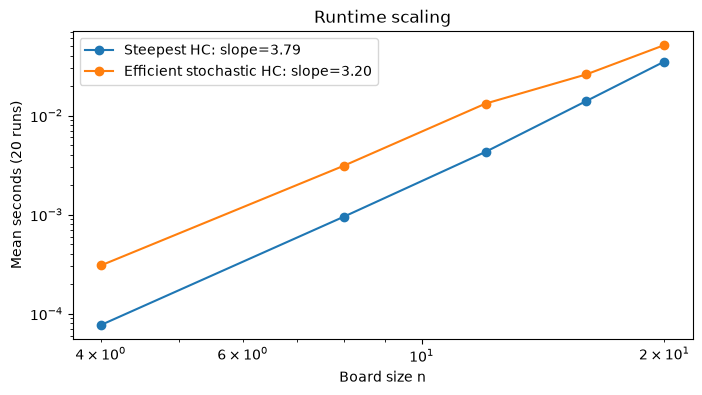

,Algorithm,n,Mean seconds,Success (%)
0,Steepest HC,4,0.00008,45.0
1,Efficient stochastic HC,4,0.00031,35.0
2,Steepest HC,8,0.00095,20.0
3,Efficient stochastic HC,8,0.00310,10.0
4,Steepest HC,12,0.00430,5.0
5,Efficient stochastic HC,12,0.01319,5.0
6,Steepest HC,16,0.01400,0.0
7,Efficient stochastic HC,16,0.02600,5.0
8,Steepest HC,20,0.03507,5.0
9,Efficient stochastic HC,20,0.05141,0.0


Nhanh nhất tại n=20: Steepest HC
conflicts() có chi phí O(n). Steepest xét n(n-1) láng giềng nên một lượt tốn O(n^3); first-choice chỉ đánh giá một láng giềng mỗi lần thử, O(n). Tuy nhiên số lần thử, patience và số bước cải thiện cũng tăng theo n. Độ dốc trên là ước lượng thực nghiệm, không chứng minh độ phức tạp tiệm cận. Thời gian ngắn có thể do bị kẹt sớm, cần đọc cùng tỷ lệ thành công.


In [26]:
scaling_rows = []
for n_size in [4, 8, 12, 16, 20]:
    boards = np.random.default_rng(4000+n_size).integers(0, n_size, size=(20, n_size))
    for name in ["Steepest HC", "Efficient stochastic HC"]:
        times, scores = [], []
        for i, board in enumerate(boards):
            start = time.perf_counter()
            result = ALGORITHMS[name](board, rng=np.random.default_rng(5000+i))
            times.append(time.perf_counter()-start)
            scores.append(result["conflicts"])
        scaling_rows.append({"Algorithm": name, "n": n_size, "Mean seconds": np.mean(times),
                             "Success (%)": 100*np.mean(np.array(scores) == 0)})
scaling_df = pd.DataFrame(scaling_rows)
fig, ax = plt.subplots(figsize=(8, 4))
slopes = {}
for name, group in scaling_df.groupby("Algorithm", sort=False):
    slope, intercept = np.polyfit(np.log(group["n"]), np.log(group["Mean seconds"]), 1)
    slopes[name] = slope
    ax.loglog(group["n"], group["Mean seconds"], "o-", label=f"{name}: slope={slope:.2f}")
    print(f"{name}: thời gian thực nghiệm xấp xỉ C*n^{slope:.2f} trong phạm vi đã đo.")
ax.set(xlabel="Board size n", ylabel="Mean seconds (20 runs)", title="Runtime scaling")
ax.legend()
plt.show()
display(scaling_df.round(5))
large = scaling_df[scaling_df["n"] == 20]
print("Nhanh nhất tại n=20:", large.loc[large["Mean seconds"].idxmin(), "Algorithm"])
print("conflicts() có chi phí O(n). Steepest xét n(n-1) láng giềng nên một lượt "
      "tốn O(n^3); first-choice chỉ đánh giá một láng giềng mỗi lần thử, O(n). "
      "Tuy nhiên số lần thử, patience và số bước cải thiện cũng tăng theo n. "
      "Độ dốc trên là ước lượng thực nghiệm, không chứng minh độ phức tạp tiệm cận. "
      "Thời gian ngắn có thể do bị kẹt sớm, cần đọc cùng tỷ lệ thành công.")


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

Mỗi kiểu di chuyển được thử 100 lần ở n=8 và n=12, với cùng tập bàn cờ ban đầu và cùng giới hạn số lần thất bại liên tiếp. Ngân sách này không có bảo đảm phủ lân cận cho các operator mới. Đường trung bình kéo dài điểm cuối của những lần kết thúc sớm. Chỉ tính thời gian đến nghiệm trên các lần thành công và luôn đọc cùng tỷ lệ thành công.

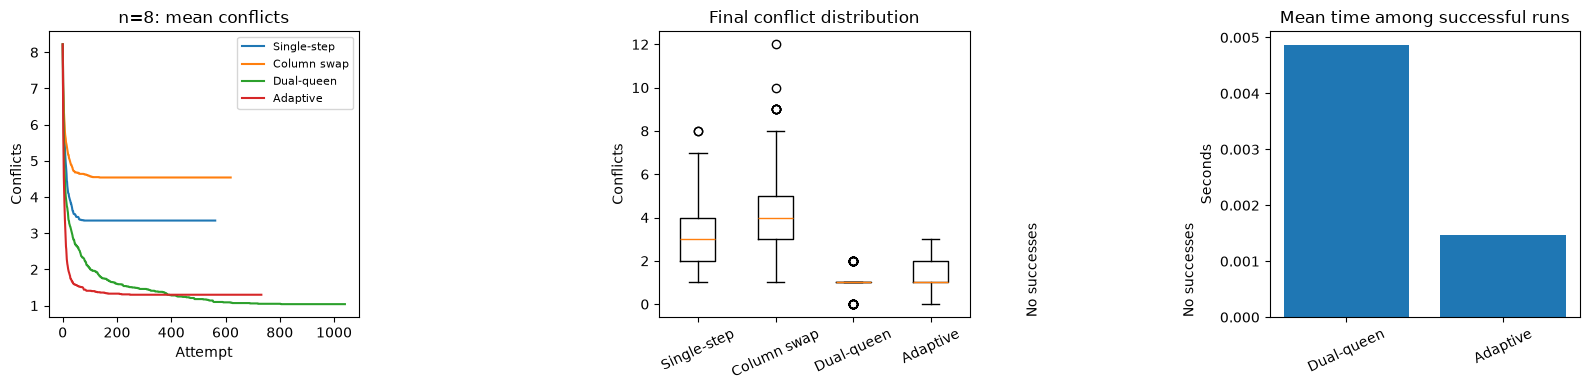

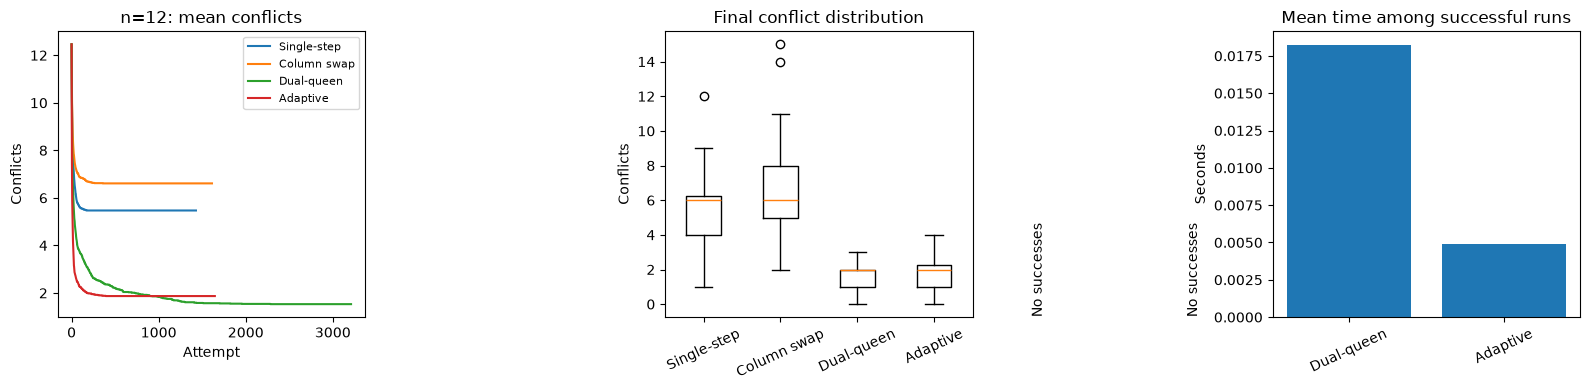

,n,Operator,Mean conflicts,Success (%),Mean successful seconds
0,8,Single-step,3.35,0.0,NaN
1,8,Column swap,4.54,0.0,NaN
2,8,Dual-queen,1.04,16.0,0.00487
3,8,Adaptive,1.30,15.0,0.00148
4,12,Single-step,5.47,0.0,NaN
5,12,Column swap,6.61,0.0,NaN
6,12,Dual-queen,1.53,4.0,0.01823
7,12,Adaptive,1.87,5.0,0.00492


n=8: operator tốt nhất theo tỷ lệ thành công, rồi xung đột: Dual-queen.
n=12: operator tốt nhất theo tỷ lệ thành công, rồi xung đột: Adaptive.
Column swap giữ nguyên tập giá trị hàng. Nếu bàn cờ đầu có hàng trùng nhau, chỉ hoán đổi không thể loại bỏ xung đột hàng để đạt nghiệm. Single-step có thể cần đi qua trạng thái không tốt hơn nên bị chặn bởi luật giảm nghiêm ngặt. Dual-queen có lân cận lớn nên cùng ngân sách chưa chắc khảo sát đủ. Adaptive ưu tiên hậu nhiều xung đột nhưng mất thêm chi phí tính xung đột từng hậu. NaN nghĩa là không có lần thành công, không phải thời gian bằng 0.


In [27]:
def adjacent_move(board, rng):
    candidate = np.array(board, copy=True)
    col = int(rng.integers(len(board)))
    valid = [r for r in [board[col]-1, board[col]+1] if 0 <= r < len(board)]
    candidate[col] = rng.choice(valid)
    return candidate

def swap_move(board, rng):
    candidate = np.array(board, copy=True)
    a, b = rng.choice(len(board), 2, replace=False)
    candidate[a], candidate[b] = candidate[b], candidate[a]
    return candidate

def dual_move(board, rng):
    candidate = np.array(board, copy=True)
    for col in rng.choice(len(board), 2, replace=False):
        row = int(rng.integers(len(board)-1))
        candidate[col] = row + (row >= board[col])
    return candidate

def adaptive_move(board, rng):
    # Keep 30% uniform exploration; otherwise target a most-conflicted queen.
    if rng.random() < 0.3:
        return single_move(board, rng)
    n = len(board)
    counts = [sum(i != j and (board[i] == board[j] or abs(board[i]-board[j]) == abs(i-j))
                  for j in range(n)) for i in range(n)]
    col = int(rng.choice(np.flatnonzero(np.array(counts) == max(counts))))
    candidate = np.array(board, copy=True)
    row = int(rng.integers(n-1))
    candidate[col] = row + (row >= board[col])
    return candidate

OPERATORS = {"Single-step": adjacent_move, "Column swap": swap_move,
             "Dual-queen": dual_move, "Adaptive": adaptive_move}
operator_rows = []
for n_size in [8, 12]:
    boards = np.random.default_rng(6000+n_size).integers(0, n_size, size=(100, n_size))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    distributions, success_times = [], []
    # Common patience budget for fair operational comparison, not a coverage guarantee
    # for operators with larger or nonuniform neighborhoods.
    budget = failure_limit(n_size)
    for name, move in OPERATORS.items():
        results, elapsed = [], []
        for i, board in enumerate(boards):
            start = time.perf_counter()
            result = efficient_stochastic_hc(board, np.random.default_rng(7000+i),
                                             patience=budget, move=move)
            elapsed.append(time.perf_counter()-start)
            results.append(result)
        scores = np.array([r["conflicts"] for r in results])
        successful_times = [t for t, s in zip(elapsed, scores) if s == 0]
        mean_success = np.mean(successful_times) if successful_times else np.nan
        operator_rows.append({"n": n_size, "Operator": name, "Mean conflicts": scores.mean(),
                              "Success (%)": 100*np.mean(scores == 0),
                              "Mean successful seconds": mean_success})
        # Carry the terminal score forward after a run has stopped.
        length = max(len(r["history"]) for r in results)
        mean_curve = np.mean([np.pad(r["history"], (0, length-len(r["history"])), mode="edge")
                              for r in results], axis=0)
        axes[0].plot(mean_curve, label=name)
        distributions.append(scores)
        success_times.append(mean_success)
    axes[0].set(title=f"n={n_size}: mean conflicts", xlabel="Attempt", ylabel="Conflicts")
    axes[0].legend(fontsize=8)
    axes[1].boxplot(distributions, tick_labels=list(OPERATORS))
    axes[1].set(title="Final conflict distribution", ylabel="Conflicts")
    axes[2].bar(list(OPERATORS), success_times)
    axes[2].set(title="Mean time among successful runs", ylabel="Seconds")
    for i, value in enumerate(success_times):
        if np.isnan(value):
            axes[2].text(i, 0, "No successes", rotation=90, va="bottom", ha="center")
    for ax in axes[1:]:
        ax.tick_params(axis="x", labelrotation=25)
    plt.tight_layout()
    plt.show()
operator_df = pd.DataFrame(operator_rows)
display(operator_df.round(5))
for n_size in [8, 12]:
    subset = operator_df[operator_df["n"] == n_size]
    best = subset.sort_values(["Success (%)", "Mean conflicts"], ascending=[False, True]).iloc[0]
    print(f"n={n_size}: operator tốt nhất theo tỷ lệ thành công, rồi xung đột: {best['Operator']}.")
print("Column swap giữ nguyên tập giá trị hàng. Nếu bàn cờ đầu có hàng trùng nhau, "
      "chỉ hoán đổi không thể loại bỏ xung đột hàng để đạt nghiệm. Single-step có thể "
      "cần đi qua trạng thái không tốt hơn nên bị chặn bởi luật giảm nghiêm ngặt. "
      "Dual-queen có lân cận lớn nên cùng ngân sách chưa chắc khảo sát đủ. "
      "Adaptive ưu tiên hậu nhiều xung đột nhưng mất thêm chi phí tính xung đột từng hậu. "
      "NaN nghĩa là không có lần thành công, không phải thời gian bằng 0.")


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [28]:
# Optional, not for credit: Genetic Algorithm is outside the required tasks.
